# Cluster State

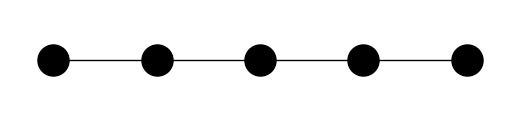

In [1]:
import networkx as nx
import matplotlib.pyplot as plt

a, b = 1, 5  # dimensions of the graph (lattice)
G = nx.grid_graph(dim=[a, b])  # there are a * b qubits

plt.figure(figsize=(5, 1))
nx.draw(G, pos={node: node for node in G}, node_size=500, node_color="black")

In [2]:
import pennylane as qp

qubits = [str(node) for node in G.nodes]
dev = qp.device("lightning.qubit", wires=qubits)


@qp.qnode(dev, interface="autograd")
def cluster_state():
    for node in qubits:
        qp.Hadamard(wires=[node])

    for edge in G.edges:
        i, j = edge
        qp.CZ(wires=[str(i), str(j)])

    return qp.state()


print(qp.draw(cluster_state)())

(0, 0): ──H─╭●──────────┤  State
(1, 0): ──H─╰Z─╭●───────┤  State
(2, 0): ──H────╰Z─╭●────┤  State
(3, 0): ──H───────╰Z─╭●─┤  State
(4, 0): ──H──────────╰Z─┤  State


# Quantum Teleporation

In [3]:
import pennylane as qp
import pennylane.numpy as np

dev = qp.device("lightning.qubit", wires=2)


@qp.qnode(dev, interface="autograd")
def one_bit_teleportation(input_state):
    # Prepare the input state
    qp.StatePrep(input_state, wires=0)

    # Prepare the cluster state
    qp.Hadamard(wires=1)
    qp.CZ(wires=[0, 1])

    # Measure the first qubit in the Pauli-X basis
    # and apply an X-gate conditioned on the outcome
    qp.Hadamard(wires=0)
    m = qp.measure(wires=[0])
    qp.cond(m == 1, qp.PauliX)(wires=1)
    qp.Hadamard(wires=1)

    # Return the density matrix of the output state
    return qp.density_matrix(wires=[1])

In [4]:
# Define helper function for random input state on n qubits
def generate_random_state(n=1):
    input_state = np.random.random(2 ** n) + 1j * np.random.random(2 ** n)
    return input_state / np.linalg.norm(input_state)


# Generate a random input state |psi> for n=1 qubit
input_state = generate_random_state()

density_matrix = np.outer(input_state, np.conj(input_state))
density_matrix_mbqc = one_bit_teleportation(input_state)

np.allclose(density_matrix, density_matrix_mbqc)

True

# Single qubit rotations = quantum gates

In [9]:
"""
R_z gate on arbitrary gate in MBQC formalism
"""

dev = qp.device("lightning.qubit", wires=1)


@qp.qnode(dev, interface="autograd")
def RZ(theta, input_state):
    # Prepare the input state
    qp.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qp.RZ(theta, wires=0)

    # Return the density matrix of the output state
    return qp.density_matrix(wires=[0])


mbqc_dev = qp.device("lightning.qubit", wires=2)


@qp.qnode(mbqc_dev, interface="autograd")
def RZ_MBQC(theta, input_state):
    # Prepare the input state
    qp.StatePrep(input_state, wires=0)

    # Prepare the cluster state
    qp.Hadamard(wires=1)
    qp.CZ(wires=[0, 1])

    # Measure the first qubit and correct the state
    qp.RZ(theta, wires=0)
    qp.Hadamard(wires=0)
    m = qp.measure(wires=[0])

    qp.cond(m == 1, qp.PauliX)(wires=1)
    qp.Hadamard(wires=1)

    # Return the density matrix of the output state
    return qp.density_matrix(wires=[1])


# Generate a random input state
input_state = generate_random_state()
theta = 2 * np.pi * np.random.random()

np.allclose(RZ(theta, input_state), RZ_MBQC(theta, input_state))

True

In [10]:
"""
R_x gate on arbitrary state in MBQC formalism
"""

dev = qp.device("lightning.qubit", wires=1)


@qp.qnode(dev, interface="autograd")
def RX(theta, input_state):
    # Prepare the input state
    qp.StatePrep(input_state, wires=0)

    # Perform the Rz rotation
    qp.RX(theta, wires=0)

    # Return the density matrix of the output state
    return qp.density_matrix(wires=[0])


mbqc_dev = qp.device("lightning.qubit", wires=3)


@qp.qnode(mbqc_dev, interface="autograd")
def RX_MBQC(theta, input_state):
    # Prepare the input state
    qp.StatePrep(input_state, wires=0)

    # Prepare the cluster state
    qp.Hadamard(wires=1)
    qp.Hadamard(wires=2)
    qp.CZ(wires=[0, 1])
    qp.CZ(wires=[1, 2])

    # Measure the qubits and perform corrections
    qp.Hadamard(wires=0)
    m1 = qp.measure(wires=[0])

    qp.RZ(theta, wires=1)
    qp.cond(m1 == 1, qp.RX)(-2 * theta, wires=2)
    qp.Hadamard(wires=1)
    m2 = qp.measure(wires=[1])

    qp.cond(m2 == 1, qp.PauliX)(wires=2)
    qp.cond(m1 == 1, qp.PauliZ)(wires=2)

    # Return the density matrix of the output state
    return qp.density_matrix(wires=[2])


# Generate a random input state
input_state = generate_random_state()
theta = 2 * np.pi * np.random.random()

np.allclose(RX(theta, input_state), RX_MBQC(theta, input_state))

True

In [11]:
"""
CNOT
"""

dev = qp.device("lightning.qubit", wires=2)


@qp.qnode(dev, interface="autograd")
def CNOT(input_state):
    # Prepare the input state
    qp.StatePrep(input_state, wires=[0, 1])
    qp.CNOT(wires=[0, 1])

    return qp.density_matrix(wires=[0, 1])


mbqc_dev = qp.device("lightning.qubit", wires=4)


@qp.qnode(mbqc_dev, interface="autograd")
def CNOT_MBQC(input_state):
    # Prepare the input state
    qp.StatePrep(input_state, wires=[0, 1])

    # Prepare the cluster state
    qp.Hadamard(wires=2)
    qp.Hadamard(wires=3)
    qp.CZ(wires=[2, 0])
    qp.CZ(wires=[2, 1])
    qp.CZ(wires=[2, 3])

    # Measure the qubits in the appropriate bases
    qp.Hadamard(wires=1)
    m1 = qp.measure(wires=[1])
    qp.Hadamard(wires=2)
    m2 = qp.measure(wires=[2])

    # Correct the state
    qp.cond(m1 == 1, qp.PauliZ)(wires=0)
    qp.cond(m2 == 1, qp.PauliX)(wires=3)
    qp.cond(m1 == 1, qp.PauliZ)(wires=3)

    # Return the density matrix of the output state
    return qp.density_matrix(wires=[0, 3])


# Generate a random 2-qubit state
input_state = generate_random_state(n=2)

np.allclose(CNOT(input_state), CNOT_MBQC(input_state))

True

# QEC

Number of qubits: 95
Number of CZ edges: 152


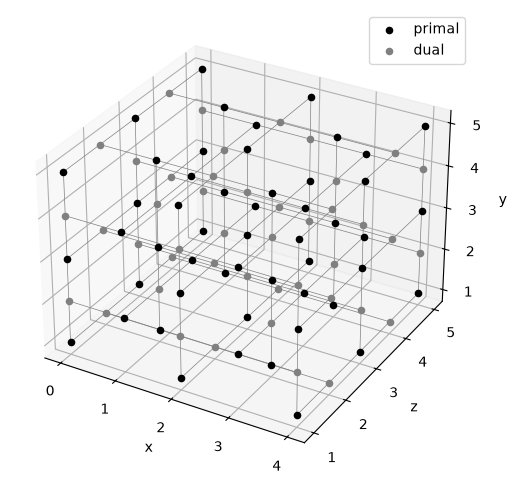

In [12]:
"""
RHG lattice surface code
(networkx/matplotlib replacement for flamingpy.codes.SurfaceCode)
"""

import itertools as it

import matplotlib.pyplot as plt
import networkx as nx


def rhg_lattice(distance, boundaries=("primal", "dual", "dual")):
    """Raussendorf-Harrington-Goyal (RHG) cluster state for the surface code.

    Qubits sit on the faces ("primal") and edges ("dual") of a cubic lattice
    whose cube corners have even coordinates: a primal qubit has two odd
    coordinates, a dual qubit has one. Every primal qubit is joined by a CZ
    to the 4 dual qubits on the edges of its face.

    The default boundaries match FlamingPy's SurfaceCode(distance), i.e.
    ec="primal", boundaries="open": primal (smooth) in x, dual (rough) in y,
    and dual in z (the time direction).
    """
    dims = (distance,) * 3 if isinstance(distance, int) else tuple(distance)

    # Primal cubes, each stored as the 6 face qubits that form its stabilizer.
    # A primal boundary drops the last layer of cubes along that axis.
    n_cubes = [d - (b == "primal") for d, b in zip(dims, boundaries)]
    primal_cubes = [
        [
            (2 * i, 2 * j + 1, 2 * k + 1),
            (2 * i + 1, 2 * j, 2 * k + 1),
            (2 * i + 1, 2 * j + 1, 2 * k),
            (2 * i + 2, 2 * j + 1, 2 * k + 1),
            (2 * i + 1, 2 * j + 2, 2 * k + 1),
            (2 * i + 1, 2 * j + 1, 2 * k + 2),
        ]
        for i, j, k in it.product(*map(range, n_cubes))
    ]

    # A dual boundary removes every qubit on its outer planes.
    def allowed(p):
        return not any(
            b == "dual" and p[a] in (0, 2 * dims[a]) for a, b in enumerate(boundaries)
        )

    G = nx.Graph(primal_cubes=primal_cubes)
    for v in {q for cube in primal_cubes for q in cube}:
        if not allowed(v):
            continue
        for a in range(3):
            if v[a] % 2:  # step along each odd axis to reach the face's edges
                for s in (-1, 1):
                    n = tuple(c + s * (i == a) for i, c in enumerate(v))
                    if allowed(n):
                        G.add_node(v, type="primal")
                        G.add_node(n, type="dual")
                        G.add_edge(v, n)
    return G


def draw_rhg(G):
    """3D plot in FlamingPy's style: primal black, dual grey, z into the page."""
    fig = plt.figure(figsize=(8, 6))
    ax = fig.add_subplot(111, projection="3d")

    for u, v in G.edges:
        (x1, y1, z1), (x2, y2, z2) = u, v
        ax.plot([x1, x2], [z1, z2], [y1, y2], color="grey", linewidth=0.5)

    for kind, color in [("primal", "black"), ("dual", "grey")]:
        x, y, z = zip(*[n for n, t in G.nodes(data="type") if t == kind])
        ax.scatter(x, z, y, c=color, label=kind, depthshade=False)

    (x0, y0, z0), (x1, y1, z1) = [list(map(f, zip(*G.nodes))) for f in (min, max)]
    ax.set_xticks(range(x0, x1 + 1))
    ax.set_yticks(range(z0, z1 + 1))
    ax.set_zticks(range(y0, y1 + 1))
    ax.set_xlabel("x")
    ax.set_ylabel("z")
    ax.set_zlabel("y")
    ax.legend()
    return fig, ax


code_distance = 3
RHG = rhg_lattice(code_distance)
print("Number of qubits:", RHG.number_of_nodes())
print("Number of CZ edges:", RHG.number_of_edges())

fig, _ = draw_rhg(RHG)
plt.show()